# 08 · Interfaz, integración y ampliación con impresiones de Anguli
**Trabajo Final · Inteligencia Artificial I · Ingeniería en Mecatrónica · UNCUYO · 2026**

**Cierre: 23/10/2026, Argentina. Versión final de desarrollo para la muestra.**

Se integra el reconocimiento de huellas con voz y alternativa manual; después se amplía el modelo para capturas de nuestro generador e impresiones de Anguli. El modelo combinado ya está ajustado y fijado. La evaluación final reservada y las pruebas con personas nuevas siguen pendientes.

Esta bitácora es de **solo lectura**: consulta evidencia publicada, configuraciones y hashes; no captura audio, genera imágenes, entrena, calibra, abre ventanas ni modifica archivos. No necesita los originales locales de Anguli, matrices de entrenamiento ni el modelo de voz local. Las salidas guardadas se ejecutaron en Linux; el control Windows se lee de los archivos enviados por el autor. No se atribuye al asistente acceso a su computadora.

In [1]:
from pathlib import Path
import csv
import hashlib
import html
import json
import platform
from IPython.display import display, HTML, Image, Markdown

RAIZ = Path.cwd().resolve()
if not (RAIZ / "config/interfaz_anguli_experimental_v1.json").is_file():
    RAIZ = RAIZ.parent
assert (RAIZ / "config/interfaz_anguli_experimental_v1.json").is_file(), "Abrir desde la raíz o notebooks/."
E = RAIZ / "documentos/resultados_adaptacion_anguli_v1"

def leer(p):
    return json.loads(Path(p).read_text(encoding="utf-8-sig"))

def filas(p):
    with Path(p).open(encoding="utf-8-sig", newline="") as f:
        return list(csv.DictReader(f))

def tabla(datos):
    claves = list(datos[0])
    cab = "".join("<th>" + html.escape(str(k)) + "</th>" for k in claves)
    cuerpo = "".join("<tr>" + "".join("<td>" + html.escape(str(r[k])) + "</td>" for k in claves) + "</tr>" for r in datos)
    display(HTML('<table><thead><tr>' + cab + '</tr></thead><tbody>' + cuerpo + '</tbody></table>'))

print("Entorno que ejecuta esta bitácora:", platform.system(), "· Python", platform.python_version())
print("Operaciones de esta bitácora: lectura y presentación de evidencia.")

Entorno que ejecuta esta bitácora: Windows · Python 3.14.0
Operaciones de esta bitácora: lectura y presentación de evidencia.


## 1. Qué se implementó y cómo se utiliza

Una ventana en español, con predominio del azul: imagen proporcional, nombre del archivo, instrucciones, Hablar, cuenta regresiva, grabación/procesamiento, resultado e identidad condicionada. Controles manuales y Detalles técnicos se despliegan cuando se necesitan; el micrófono puede cambiarse. Tkinter/ttk evita una biblioteca gráfica adicional y utiliza Pillow ya instalado.

La voz es la interacción principal. La alternativa manual ejecuta exactamente las mismas acciones y respeta las mismas precondiciones. Una acción manual se informa como manual, no como éxito acústico. La aplicación sigue operativa para huellas si el audio falla y el modelo de huellas está disponible.

**Inicio de la versión para la muestra, desde PowerShell:**
```powershell
.\.venv\Scripts\python.exe src/interfaz.py --config config/interfaz_anguli_experimental_v1.json
```
El nombre experimental conserva trazabilidad. El comando sin `--config` abre el respaldo anterior de 72 columnas. No es necesario ejecutar este notebook para iniciar la aplicación.

In [2]:
cfg = leer(RAIZ / "config/interfaz_anguli_experimental_v1.json")
res = leer(E / "modelo/resumen.json")
viejo = leer(RAIZ / "documentos/resultados_etapa06/03_rechazo/resumen.json")
voz = leer(RAIZ / "documentos/resultados_etapa07/parametros_elegidos.json")
actual = leer(RAIZ / "config/interfaz_v1.json")
assert cfg["audio"] == actual["audio"], "Las configuraciones no conservan el mismo audio."
tabla([
    {"Módulo": "Huellas principal", "Modelo": res["fecha_utc"], "Método": "K-means, k=3", "Características": f"{res['columnas_utilizadas']}/{res['columnas_entrada']}", "PCA en inferencia": "No"},
    {"Módulo": "Huellas respaldo", "Modelo": viejo["fecha_utc"], "Método": "K-means, k=3", "Características": f"{viejo['columnas_utilizadas']}/{viejo['columnas_entrada']}", "PCA en inferencia": "No"},
    {"Módulo": "Voz", "Modelo": Path(cfg["audio"]["modelo"]).name, "Método": f"K-NN k={voz['k']}, {voz['votos']}", "Características": "160", "PCA en inferencia": "No"},
])
print("Umbral combinado:", leer(E / "modelo/umbral.json")["umbral"])
print("El modelo de voz conserva su ruta local; su ausencia no impide leer esta bitácora.")

Módulo,Modelo,Método,Características,PCA en inferencia
Huellas principal,20261023T222326_850333Z,"K-means, k=3",36/144,No
Huellas respaldo,20261023T021746_872267Z,"K-means, k=3",72/144,No
Voz,20261023T033845_362145Z,"K-NN k=1, uniform",160,No


Umbral combinado: 4.136012624996962
El modelo de voz conserva su ruta local; su ausencia no impide leer esta bitácora.


## 2. Flujo de un ciclo y estados

**Huella:** seleccionar captura → estado pendiente → Reconocer → normalización en memoria → 144 características GLCM → selección de 36 y escalado guardados → distancia al centroide más cercano → aceptación o rechazo. Si fue autorizada, Identificar revela la identidad. No se ejecuta K-means de nuevo ni se aprende de la consulta.

**Voz:** Hablar → cuenta regresiva → GRABANDO → captura de duración configurada → preprocesamiento y validación existentes → 160 características → escalado guardado → K-NN → acción compartida con el control manual. No hay escucha permanente ni detector nuevo del final de palabra. Audio inválido informa el motivo y no ejecuta una acción. Una palabra fuera del vocabulario puede convertirse en alguno de los tres comandos; no se incorporó una cuarta clase.

Las operaciones lentas se realizan en trabajadores; Tk se actualiza desde su hilo principal por cola. Se bloquean acciones incompatibles y se invalidan respuestas tardías mediante tokens de sesión/consulta. Salir por voz, manual o cierre de ventana pide confirmación; cancelar conserva la sesión.

In [3]:
tabla([
    {"Estado": "Sin imagen", "Condición": "Reconocer requiere seleccionar una consulta."},
    {"Estado": "Pendiente", "Condición": "La imagen actual todavía no tiene autorización."},
    {"Estado": "Autorizada", "Condición": "Evaluación completa; distancia ≤ umbral. Identificar puede revelar identidad."},
    {"Estado": "No autorizada", "Condición": "Evaluación completa; distancia > umbral. No se revela identidad candidata."},
    {"Estado": "Error", "Condición": "No se pudo leer/procesar. No se convierte en rechazo biométrico."},
])
print("Cambiar imagen borra decisión e identidad. Cancelar el selector conserva el estado.")
print("Una evaluación fallida invalida la autorización anterior para ese intento.")

Estado,Condición
Sin imagen,Reconocer requiere seleccionar una consulta.
Pendiente,La imagen actual todavía no tiene autorización.
Autorizada,Evaluación completa; distancia ≤ umbral. Identificar puede revelar identidad.
No autorizada,Evaluación completa; distancia > umbral. No se revela identidad candidata.
Error,No se pudo leer/procesar. No se convierte en rechazo biométrico.


Cambiar imagen borra decisión e identidad. Cancelar el selector conserva el estado.
Una evaluación fallida invalida la autorización anterior para ese intento.


## 3. Preparar captura y entradas admitidas

Seleccionar una base limpia en **Preparar captura** genera automáticamente una consulta con un perfil existente y una semilla aleatorios elegidos antes de inferir. No se buscan capturas favorables. Generar nueva captura repite el sorteo. Opciones avanzadas permite ver parámetros y activar elección manual para reproducirlos; abrir el panel no regenera.

Usar esta captura transfiere la imagen original en memoria y deja el reconocimiento pendiente. La normalización ocurre al reconocer. Guardar consulta es opcional y conserva base, captura y receta; no se guardan consultas permanentemente por defecto.

- Captura de nuestro generador: abrir directamente.
- Impresión de Anguli con configuración ensayada: abrir directamente; no añadir nuestras deformaciones.
- Base limpia Fingerprints: pasar por Preparar captura.
- Otras configuraciones, nuevas identidades o huellas reales: alcance no validado.

La identidad se obtiene del contenido. El nombre/carpeta/semilla no entra al reconocedor. Mantener semilla no garantiza salida idéntica si cambia ejecutable o configuración.

## 4. Por qué se amplió el modelo

El modelo anterior rechazó las cinco impresiones iniciales. Después, en las 125 impresiones de desarrollo, rechazó las 75 autorizadas y las 50 intrusas, sin errores de procesamiento. La normalización no convierte texturas de distintos procedimientos en representaciones idénticas. Las impresiones Anguli mostraban textura más fragmentada y diferencias de homogeneidad, contraste y correlación. Esto sugiere una diferencia de distribución; no prueba una única causa ni que sean simplemente más deformadas.

Se conservó el extractor y se amplió el desarrollo con imágenes del procedimiento nuevo. Las cinco bases regeneradas coincidieron con las originales y no hubo duplicados exactos en las 150 impresiones. Ruido, rayaduras, rotación y traslación se configuraron en cero, con 30 impresiones por identidad, semillas 101/202/303/404/505, distribución Natural y un hilo. Se sigue tratando de huellas sintéticas.

In [4]:
cat = filas(E / "catalogo_desarrollo.csv")
manifest = filas(E / "manifiesto_anguli.csv")
tabla([
    {"Fuente": fuente, "Partición": parte, "Grupo": grupo,
     "Cantidad": sum(r["fuente"] == fuente and r["particion"] == parte and r["grupo"] == grupo for r in cat)}
    for fuente, parte, grupo in [
        ("anterior", "entrenamiento", "autorizado"), ("anguli", "entrenamiento", "autorizado"),
        ("anterior", "validacion", "autorizado"), ("anguli", "validacion", "autorizado"),
        ("anterior", "validacion", "intruso"), ("anguli", "validacion", "intruso")]
])
assert len(cat) == 295
assert sum(r["particion"] == "entrenamiento" for r in cat) == 180
assert sum(r["particion"] == "control_apartado" for r in manifest) == 25
assert all(r["grupo"] == "autorizado" for r in cat if r["particion"] == "entrenamiento")
print("180 capturas de ajuste, 115 de validación y 25 controles separados.")
print("Las 50 muestras originales de prueba no forman parte de este catálogo.")

Fuente,Partición,Grupo,Cantidad
anterior,entrenamiento,autorizado,120
anguli,entrenamiento,autorizado,60
anterior,validacion,autorizado,30
anguli,validacion,autorizado,15
anterior,validacion,intruso,20
anguli,validacion,intruso,50


180 capturas de ajuste, 115 de validación y 25 controles separados.
Las 50 muestras originales de prueba no forman parte de este catálogo.


## 5. Selección, K-means y umbral del combinado

Se conserva el plan previo de comparar 144, 72 y 36 columnas mediante cinco pliegues dentro del entrenamiento. Cada pliegue vuelve a seleccionar, escalar y ajustar K-means. Se elige mayor ARI medio; empate, más columnas. La selección y correspondencia utilizan identidades de entrenamiento; K-means recibe vectores sin etiquetas. Los intrusos no ajustan los centroides.

Cada captura pesa uno: 120 anteriores y 60 Anguli. La fuente anterior aporta 2/3; no se duplicaron imágenes para equilibrar. Esta ponderación no se optimizó consultando control. La CV es interna con variantes de bases conocidas y no mide generalización a nuevos dedos.

Después del ajuste se congela selección, escalado, centroides y correspondencia. El umbral se calibra con validación de ambas fuentes, minimizando (FAR+FRR)/2; desempata por menor FAR y menor umbral. Sus métricas se informan como calibración, no como prueba final.

In [5]:
tabla(filas(E / "comparacion_cv.csv"))
print("Columnas elegidas:", res["columnas_utilizadas"])
print("Ponderación registrada:", res["ponderacion"])
print("Umbral fijado:", res["resultado_calibracion"]["umbral"])
assert res["columnas_utilizadas"] == 36
for nombre, esperado in res["archivos_sha256"].items():
    datos = (E / "modelo" / nombre).read_bytes()
    # Misma tolerancia exclusiva de saltos de línea que el cargador publicado.
    candidatos = [datos] if not nombre.endswith(".json") else [datos, datos.replace(b"\r\n", b"\n"), datos.replace(b"\r\n", b"\n").replace(b"\n", b"\r\n")]
    assert esperado in {hashlib.sha256(x).hexdigest() for x in candidatos}, nombre
print("Integridad de parámetros, umbral y correspondencia: verificada.")

columnas,ari_medio,ari_minimo,coincidencia_media
144,0.29307668166080986,0.26482701812191106,0.49444444444444446
72,0.8129287568664854,0.5259287925696594,0.8333333333333334
36,1.0,1.0,1.0


Columnas elegidas: 36
Ponderación registrada: Cada captura pesa uno: anterior 2/3, Anguli 1/3; sin duplicación ni sobremuestreo.
Umbral fijado: 4.136012624996962
Integridad de parámetros, umbral y correspondencia: verificada.


## 6. Validación y control, sin mezclar sus interpretaciones

Las tablas se leen de los resultados guardados. El modelo se fijó antes de consultar las 25 imágenes de control. No se reajustó después del falso rechazo. Un resultado aceptado solo cuenta como identificación correcta si también coincide la identidad. La distancia euclidiana no es probabilidad y el voto k=1 de audio no equivale a 100 % de confianza.

In [6]:
tabla([
    {"Fuente": r["fuente"], "Grupo": r["grupo"], "Consultas de validación": r["n"],
     "Aceptadas": r["aceptadas"], "Rechazadas": r["rechazadas"],
     "Identificaciones correctas": r["identificadas_correctamente"]}
    for r in res["validacion_modelo_combinado"]
])
linux = leer(E / "control/resumen_control.json")
windows = leer(E / "control_windows/resumen_control.json")
tabla(windows["resultados"])
print("Control Linux:", linux["fecha_utc"], "UTC")
print("Control Windows del autor:", windows["fecha_utc"], "UTC")
print("Son las mismas 25 imágenes, no 50 observaciones independientes.")

Fuente,Grupo,Consultas de validación,Aceptadas,Rechazadas,Identificaciones correctas
anterior,autorizado,30,29,1,29
anterior,intruso,20,0,20,0
anguli,autorizado,15,15,0,15
anguli,intruso,50,0,50,0


identidad,n,errores,aceptadas,identificadas_correctamente
A01,5,0,5,5
A02,5,0,5,5
A03,5,0,4,4
I01,5,0,0,0
I02,5,0,0,0


Control Linux: 20261023T222420_933503Z UTC
Control Windows del autor: 20261023T223300_873346Z UTC
Son las mismas 25 imágenes, no 50 observaciones independientes.


In [7]:
cl = filas(E / "control/consultas_control.csv")
cw = filas(E / "control_windows/consultas_control.csv")
assert len(cl) == len(cw) == 25
for a, b in zip(cl, cw):
    assert a["archivo"] == b["archivo"]
    assert a["aceptada"] == b["aceptada"]
    assert a["identidad_predicha"] == b["identidad_predicha"]
    assert abs(float(a["distancia"]) - float(b["distancia"])) < 1e-12
assert all(not r["error"] for r in cw)
fallos = [r for r in cw if r["grupo_real"] == "autorizado" and r["aceptada"] == "False"]
tabla([{ "Identidad": r["identidad_real"], "Impresión": r["impresion"],
         "Distancia": r["distancia"], "Umbral": windows["umbral"], "Resultado": "Falso rechazo"} for r in fallos])
print("Reproducción Windows/Linux concordante; sin errores de procesamiento.")
print("No se eliminaron los rechazos ni se elevó el umbral a partir del control.")

Identidad,Impresión,Distancia,Umbral,Resultado
A03,26,6.505319363676789,4.136012624996962,Falso rechazo


Reproducción Windows/Linux concordante; sin errores de procesamiento.
No se eliminaron los rechazos ni se elevó el umbral a partir del control.


## 7. Verificaciones de software y demostración

Linux: pruebas de estados, recursos ausentes, reconocimiento/identificación condicionada, generación/reproducción de capturas y operaciones bloqueadas. La coordinación de voz se probó con dobles explícitos, sin atribuirles aciertos acústicos. Para el combinado aprobaron cuatro pruebas nuevas y diez de integración anteriores; además se recorrió una ventana Tk real con configuración alternativa, impresión autorizada, intrusa rechazada y captura preparada.

Windows del autor: los archivos del control recibidos reproducen las 25 consultas y distancias. El autor también informó funcionamiento del preparador y reconocimiento de impresiones regeneradas con igual configuración; no se dispone de conteo individual completo de todos esos intentos. El audio conserva su evidencia histórica de voz conocida; no se realizó aquí una nueva evaluación acústica controlada.

La imagen siguiente corresponde a la ventana **real en Linux**, con impresión Anguli A01 autorizada e identificada. El aviso de funciones limitadas refleja audio no disponible en ese entorno. No es una captura de Windows del autor.

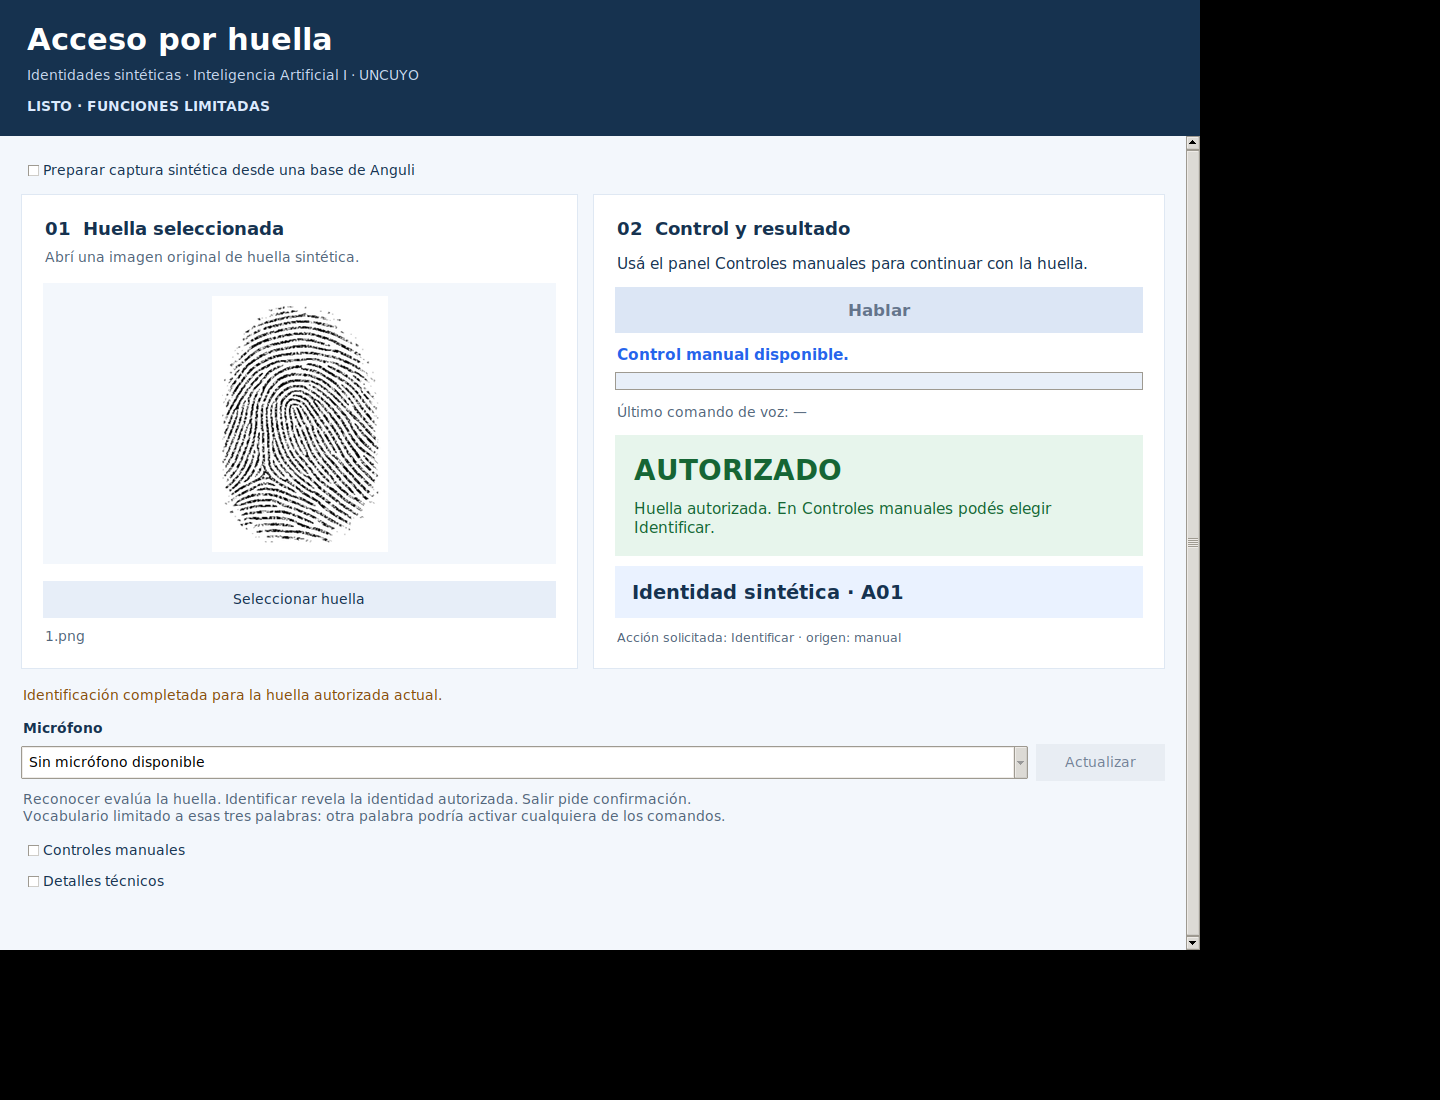

In [8]:
captura = E / "verificaciones/ventana_anguli.png"
assert captura.is_file(), "Falta la evidencia visual del paquete combinado."
display(Image(filename=str(captura), width=900))

## 8. Cierre, limitaciones y reproducción

Se fija el combinado como **modelo final de desarrollo entregable para la muestra**. No hace falta seguir entrenando para intentar ocultar el falso rechazo. Se conserva el modelo anterior y toda la evidencia histórica. Los nombres de archivo se mantienen hasta una reorganización posterior.

Pendientes: evaluación final reservada con protocolo fijado antes de usarla; pruebas de voz con personas nuevas y comando realmente intentado; informe/presentación final. La prueba original cubre capturas de nuestro generador y no valida por sí sola otras configuraciones de Anguli. Las cinco bases del control son conocidas y correlacionadas; no se garantiza reconocimiento de huellas reales o nuevas identidades.

**Comprobaciones opcionales en PowerShell:**
```powershell
.\.venv\Scripts\python.exe -m unittest discover -s tests -p "test_modelo_anguli.py" -v
.\.venv\Scripts\python.exe src/probar_modelo_anguli.py --control
```
Repetir el control comprueba reproducción, no agrega datos independientes. El ajuste se reproduce con `adaptar_modelo_anguli.py` solo de forma explícita, en una carpeta nueva; no es una etapa de inicio de la aplicación.

Documentación: [cierre 08](../documentos/cierre_etapa08.md), [modelo combinado](../documentos/modelo_combinado_anguli_v1.md), [interfaz](../documentos/interfaz_integracion.md), [preparador](../documentos/preparacion_capturas.md), [asistencia de IA](../documentos/uso_ia_generativa.md).